# 03 · Exploratory Data Analysis

## Problem Definition

**What is the dataset about?**
16,109 matches from Europe's top 5 football leagues (Premier League, La Liga, Serie A, Bundesliga, Ligue 1) across 9 seasons (2017–18 to 2025–26). Each row is one match, with the result, shots, fouls, cards, referee and crowd attendance.

During COVID-19, matches were played in empty stadiums. This gives a natural experiment: the same teams and referees, with and without fans.

**Main questions**
1. Did home advantage drop without crowds?
2. Did the referee's bias against away teams disappear without crowds?
3. Did home team performance (shots) drop without crowds?
4. Does the effect grow with the size of the crowd?

**Expected insights**
We expect home teams to win less in empty stadiums, and referees to give away teams fewer extra fouls and cards when there's no crowd to pressure them.

## 1. Data Loading & Structure

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/clean/matches.csv", parse_dates=["date"])

In [29]:
df.head()

,league,season,date,home_team,away_team,venue,referee,attendance,capacity_est,attendance_pct,...,home_fouls,away_fouls,home_yellows,away_yellows,home_reds,away_reds,foul_diff,yellow_diff,red_diff,awarded
0,Bundesliga,2017,2017-08-18,Bayern Munich,Leverkusen,Allianz Arena,Tobias Stieler,75000.0,75000.0,1.000000,...,13.0,17.0,1.0,2.0,0.0,0.0,4.0,1.0,0.0,False
1,Bundesliga,2017,2017-08-19,Hamburger SV,Augsburg,Volksparkstadion,Daniel Siebert,49449.0,57000.0,0.867526,...,18.0,16.0,4.0,3.0,0.0,0.0,-2.0,-1.0,0.0,False
2,Bundesliga,2017,2017-08-19,Hertha BSC,Stuttgart,Olympiastadion Berlin,Sascha Stegemann,44751.0,74669.0,0.599325,...,18.0,12.0,2.0,1.0,0.0,0.0,-6.0,-1.0,0.0,False
3,Bundesliga,2017,2017-08-19,Hoffenheim,Werder Bremen,Dietmar-Hopp-Stadion,Guido Winkmann,30150.0,30150.0,1.000000,...,17.0,15.0,1.0,3.0,0.0,0.0,-2.0,2.0,0.0,False
4,Bundesliga,2017,2017-08-19,Mainz 05,Hannover 96,Opel Arena,Felix Brych,28279.0,34000.0,0.831735,...,18.0,14.0,3.0,5.0,0.0,0.0,-4.0,2.0,0.0,False


In [30]:
df.shape

(16109, 33)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16109 entries, 0 to 16108
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   league          16109 non-null  str           
 1   season          16109 non-null  int64         
 2   date            16109 non-null  datetime64[us]
 3   home_team       16109 non-null  str           
 4   away_team       16109 non-null  str           
 5   venue           16109 non-null  str           
 6   referee         16109 non-null  str           
 7   attendance      16063 non-null  float64       
 8   capacity_est    16045 non-null  float64       
 9   attendance_pct  16061 non-null  float64       
 10  crowd_status    16109 non-null  str           
 11  crowd           16063 non-null  float64       
 12  home_goals      16109 non-null  int64         
 13  away_goals      16109 non-null  int64         
 14  result          16109 non-null  str           
 15  home_points  

In [32]:
df.describe()

,season,date,attendance,capacity_est,attendance_pct,crowd,home_goals,away_goals,home_points,goal_diff,...,sot_diff,home_fouls,away_fouls,home_yellows,away_yellows,home_reds,away_reds,foul_diff,yellow_diff,red_diff
count,16109.000000,16109,16063.000000,16045.000000,16061.000000,16063.000000,16109.000000,16109.000000,16109.000000,16109.000000,...,16108.000000,16109.000000,16109.000000,16109.000000,16109.000000,16109.000000,16109.000000,16109.000000,16109.000000,16109.000000
mean,2020.970762,2021-12-29 09:19:19.178099,27130.691340,39443.989841,0.684571,0.867895,1.536408,1.252592,1.558135,0.283817,...,0.840390,12.068037,12.313179,1.915203,2.148799,0.089888,0.101931,0.245142,0.233596,0.012043
min,2017.000000,2017-08-04 00:00:00,0.000000,5862.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-9.000000,...,-18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-23.000000,-7.000000,-3.000000
25%,2019.000000,2019-10-06 00:00:00,12097.000000,23566.000000,0.543011,1.000000,1.000000,0.000000,0.000000,-1.000000,...,-2.000000,9.000000,9.000000,1.000000,1.000000,0.000000,0.000000,-3.000000,-1.000000,0.000000
50%,2021.000000,2021-12-19 00:00:00,23515.000000,34832.000000,0.810146,1.000000,1.000000,1.000000,1.000000,0.000000,...,1.000000,12.000000,12.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2023.000000,2024-03-03 00:00:00,40118.500000,52758.000000,0.953781,1.000000,2.000000,2.000000,3.000000,1.000000,...,3.000000,15.000000,15.000000,3.000000,3.000000,0.000000,0.000000,4.000000,1.000000,0.000000
max,2025.000000,2026-05-24 00:00:00,97939.000000,97939.000000,1.000000,1.000000,9.000000,9.000000,3.000000,9.000000,...,17.000000,29.000000,31.000000,9.000000,9.000000,3.000000,2.000000,24.000000,7.000000,2.000000
std,2.576990,NaN,20340.732003,19245.213132,0.334045,0.338615,1.299985,1.167901,1.319911,1.822459,...,3.756699,3.905701,4.018496,1.366122,1.410529,0.305955,0.319337,5.180543,1.746044,0.425887


**Notes:**
- 16,109 matches and 33 columns.
- Home teams score more on average (1.54 vs 1.25 goals) and have more shots (13.5 vs 11.1). That's home advantage in the raw numbers.
- `attendance` ranges from 0 (ghost games) to 97,939 (Camp Nou).
- The `_diff` columns are from the home team's view: positive means in favour of the home team, or more against the away team.

## 2. Missing Values & Duplicates

In [33]:
df.isnull().sum()

league             0
season             0
date               0
home_team          0
away_team          0
venue              0
referee            0
attendance        46
capacity_est      64
attendance_pct    48
crowd_status       0
crowd             46
home_goals         0
away_goals         0
result             0
home_points        0
goal_diff          0
home_shots         0
away_shots         0
home_sot           0
away_sot           1
shot_diff          0
sot_diff           1
home_fouls         0
away_fouls         0
home_yellows       0
away_yellows       0
home_reds          0
away_reds          0
foul_diff          0
yellow_diff        0
red_diff           0
awarded            0
dtype: int64

Only three columns have missing values, and they're all expected from the cleaning step:
- `attendance` and `crowd`: 46 matches where attendance wasn't recorded outside the COVID period (`crowd_status = unknown`).
- `attendance_pct`: those 46, plus 2 Spezia matches at a temporary stadium.
- `capacity_est`: also a few ghost games at venues that never hosted a normal match (no normal crowd to estimate from). Their `attendance_pct` is still 0.
- `away_sot` / `sot_diff`: one value removed as a data-entry error.

In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.duplicated(subset=["league", "season", "home_team", "away_team"]).sum()

np.int64(0)

No duplicate rows, and no match appears twice.

For the crowd analysis we drop the 46 `unknown` matches, since we don't know if fans were there.

In [36]:
df = df[df["crowd_status"] != "unknown"]
df["crowd_label"] = df["crowd"].map({1: "Fans", 0: "No fans"})
df.shape

(16063, 34)

## 3. Univariate Analysis

### 3.1 Match results

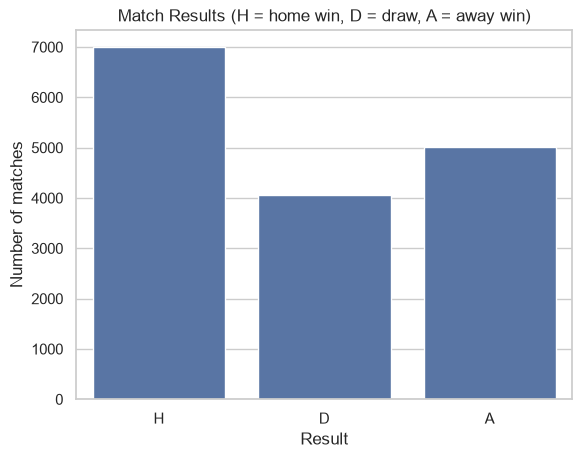

result
H    0.435473
A    0.312208
D    0.252319
Name: proportion, dtype: float64

In [37]:
sns.countplot(data=df, x="result", order=["H", "D", "A"])
plt.title("Match Results (H = home win, D = draw, A = away win)")
plt.xlabel("Result")
plt.ylabel("Number of matches")
plt.show()

df["result"].value_counts(normalize=True)

**Insight:** home teams win about 44% of matches, away teams 31%, and 25% are draws. Home advantage clearly exists overall.

### 3.2 Crowd status

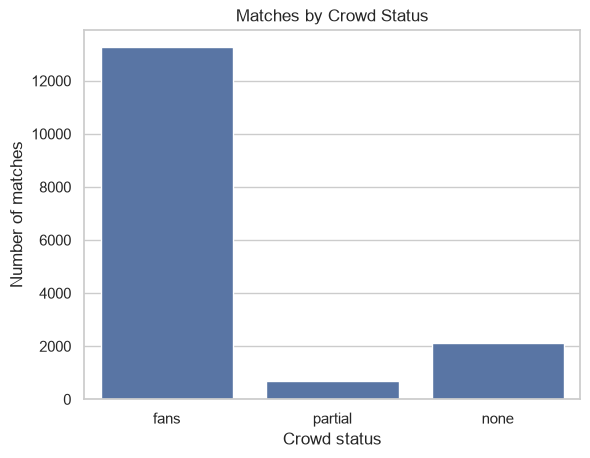

crowd_status
fans       13262
none        2122
partial      679
Name: count, dtype: int64

In [38]:
sns.countplot(data=df, x="crowd_status", order=["fans", "partial", "none"])
plt.title("Matches by Crowd Status")
plt.xlabel("Crowd status")
plt.ylabel("Number of matches")
plt.show()

df["crowd_status"].value_counts()

**Insight:** about 13% of matches (2,122) were ghost games, which gives a big enough sample to compare against matches with fans. Only 679 had a partial crowd.

### 3.3 Attendance

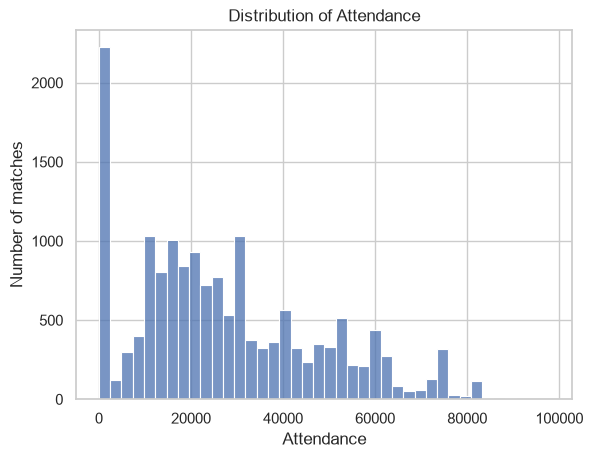

In [39]:
sns.histplot(data=df, x="attendance", bins=40)
plt.title("Distribution of Attendance")
plt.xlabel("Attendance")
plt.ylabel("Number of matches")
plt.show()

**Insight:** there's a big spike at 0 (the ghost games). The rest is right-skewed: most matches have 10,000–40,000 fans, and only a few clubs (Barcelona, Dortmund, Real Madrid, Man United) get over 70,000.

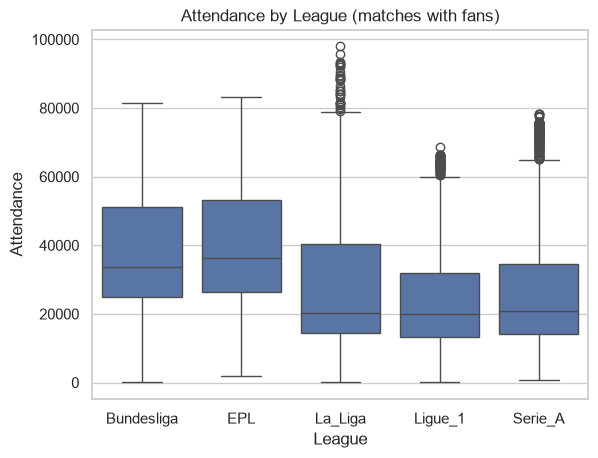

In [40]:
sns.boxplot(data=df[df["crowd"] == 1], x="league", y="attendance")
plt.title("Attendance by League (matches with fans)")
plt.xlabel("League")
plt.ylabel("Attendance")
plt.show()

**Insight:** the Premier League (median around 36,000) and Bundesliga (34,000) have the biggest crowds, almost double La Liga, Serie A and Ligue 1 (around 20,000). The dots above the boxes are outliers, which are big clubs with huge stadiums like Barcelona and Inter, not data errors.

### 3.4 Goal difference and yellow card difference

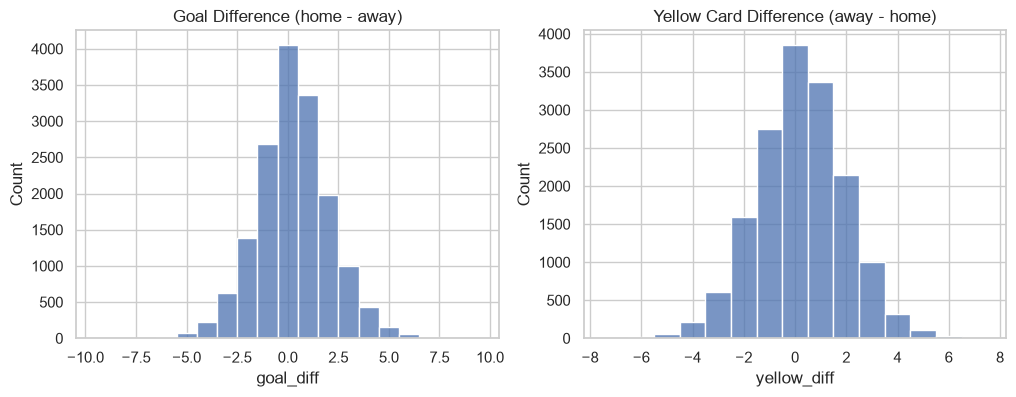

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="goal_diff", discrete=True, ax=axes[0])
axes[0].set_title("Goal Difference (home - away)")

sns.histplot(data=df, x="yellow_diff", discrete=True, ax=axes[1])
axes[1].set_title("Yellow Card Difference (away - home)")

plt.show()

**Insight:** both are centered slightly above 0. Home teams usually win by a small margin, and away teams get slightly more yellow cards. Most matches are within ±2 goals and ±2 cards.

## 4. Bivariate Analysis

### 4.1 Q1: Did home advantage drop without fans?

In [42]:
home_win = df.groupby("crowd_label")["result"].apply(lambda r: (r == "H").mean() * 100)
home_win

crowd_label
Fans       44.107309
No fans    39.868049
Name: result, dtype: float64

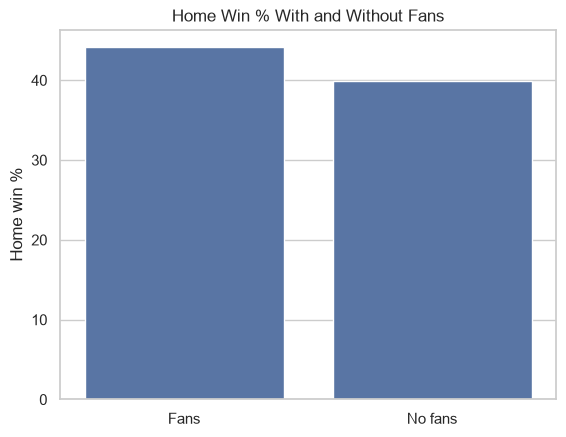

In [43]:
sns.barplot(x=home_win.index, y=home_win.values)
plt.title("Home Win % With and Without Fans")
plt.xlabel("")
plt.ylabel("Home win %")
plt.show()

**Insight:** home teams won **44.1%** of matches with fans, but only **39.9%** without. Away wins went up from 30.7% to 34.8%.

Note: "Fans" here includes the 679 partial-crowd matches. Below we compare **normal matches** before and after COVID with ghost games, to make sure the restricted crowds don't affect the result.

In [44]:
before = df[df["date"] < "2020-03-01"]
ghost = df[df["crowd_status"] == "none"]
after = df[df["date"] >= "2022-07-01"]

comparison = pd.DataFrame({
    "Before COVID": before["result"].value_counts(normalize=True) * 100,
    "Ghost games": ghost["result"].value_counts(normalize=True) * 100,
    "After COVID": after["result"].value_counts(normalize=True) * 100,
}).loc[["H", "D", "A"]].round(1)
comparison

,Before COVID,Ghost games,After COVID
result,,,
H,45.0,39.9,43.8
D,25.0,25.3,25.3
A,30.0,34.8,31.0


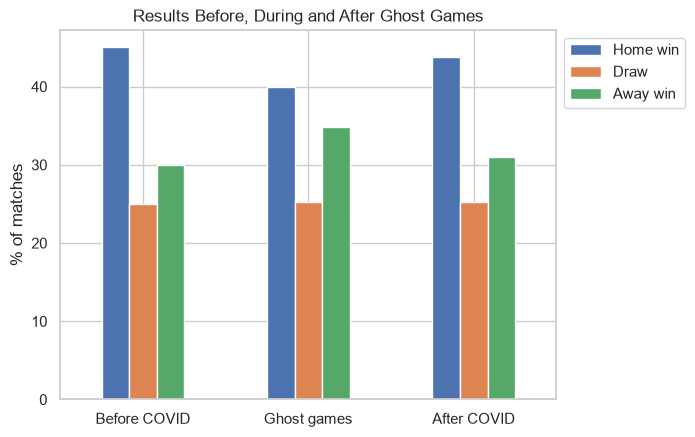

In [45]:
comparison.T.plot(kind="bar")
plt.title("Results Before, During and After Ghost Games")
plt.ylabel("% of matches")
plt.xticks(rotation=0)
plt.legend(["Home win", "Draw", "Away win"], bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**Insight:** before COVID (4,904 matches), home teams won **45.0%** and away teams **30.0%**, a **15-point gap**. In ghost games it was **39.9% vs 34.8%**, only a **5-point gap**. After fans came back (2022–23 to 2025–26, 7,072 matches), it returned to **43.8% vs 31.0%**, a **13-point gap**.

Home advantage shrank by about **two thirds** without fans, then came back almost fully with them. Draws stayed the same (25%) in all three periods, so the lost home wins turned into away wins.

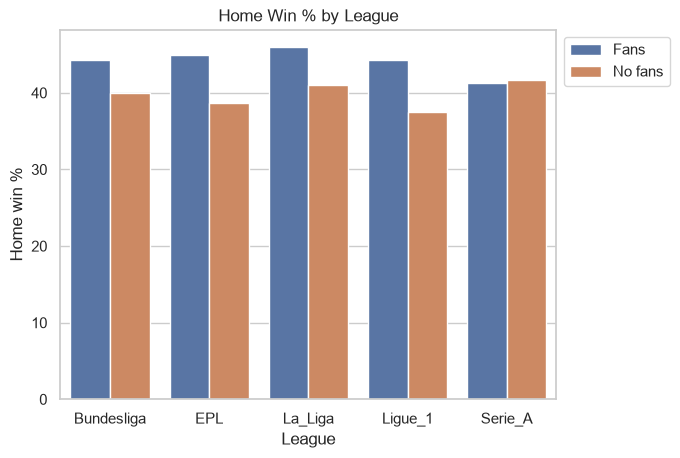

In [46]:
by_league = df.groupby(["league", "crowd_label"])["result"].apply(lambda r: (r == "H").mean() * 100).reset_index()
by_league.columns = ["league", "crowd_label", "home_win_pct"]

sns.barplot(data=by_league, x="league", y="home_win_pct", hue="crowd_label")
plt.title("Home Win % by League")
plt.xlabel("League")
plt.ylabel("Home win %")
plt.legend(title="", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**Insight:** the drop happened in 4 of 5 leagues, biggest in **Ligue 1 (−6.7 points)** and the **Premier League (−6.3)**. **Serie A** didn't drop at all (41.2% with fans vs 41.6% without), so the crowd effect isn't the same everywhere.

### 4.2 Q2: Did referee bias disappear without fans?

In [47]:
referee = df.groupby("crowd_label")[["foul_diff", "yellow_diff"]].mean()
referee

,foul_diff,yellow_diff
crowd_label,,
Fans,0.319561,0.270497
No fans,-0.228558,-0.005184


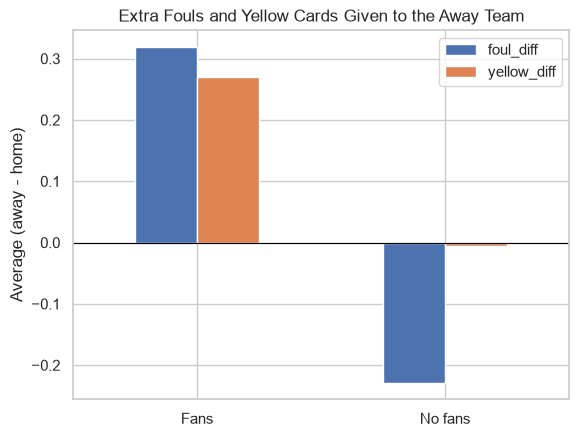

In [48]:
referee.plot(kind="bar")
plt.title("Extra Fouls and Yellow Cards Given to the Away Team")
plt.xlabel("")
plt.ylabel("Average (away - home)")
plt.xticks(rotation=0)
plt.axhline(0, color="black", linewidth=0.8)
plt.show()

**Insight:** this is the clearest result. With fans, away teams get **+0.32 more fouls** and **+0.27 more yellow cards** per match than home teams. Without fans, the yellow card gap drops to **0**, and fouls even flip slightly (−0.23). The referee's bias against away teams disappeared when the crowd left.

### 4.3 Q3: Did home team performance drop?

In [49]:
shots = df.groupby("crowd_label")[["shot_diff", "sot_diff"]].mean()
shots

,shot_diff,sot_diff
crowd_label,,
Fans,2.557636,0.887159
No fans,1.348728,0.522149


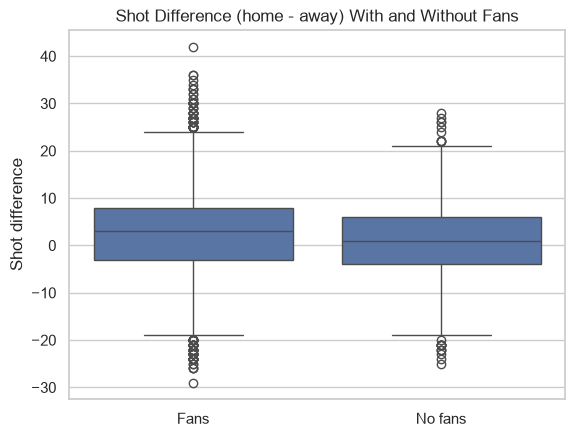

In [50]:
sns.boxplot(data=df, x="crowd_label", y="shot_diff")
plt.title("Shot Difference (home - away) With and Without Fans")
plt.xlabel("")
plt.ylabel("Shot difference")
plt.show()

**Insight:** home teams had **2.6 more shots** than away teams with fans, but only **1.35** without, roughly half. Shots aren't decided by the referee, so this suggests players also play differently without their fans. Home advantage comes from **both** the referee and the players.

### 4.4 Q4: Does the effect grow with crowd size?

In [51]:
df["crowd_size"] = pd.cut(df["attendance_pct"], bins=[-0.01, 0, 0.25, 0.5, 0.75, 1],
                          labels=["0%", "1-25%", "25-50%", "50-75%", "75-100%"])

by_size = df.groupby("crowd_size", observed=True)[["home_points", "yellow_diff"]].mean()
by_size["matches"] = df["crowd_size"].value_counts()
by_size

,home_points,yellow_diff,matches
crowd_size,,,
0%,1.449105,-0.005184,2122
1-25%,1.629213,0.157303,445
25-50%,1.507637,0.335130,1113
50-75%,1.585797,0.273136,3112
75-100%,1.577732,0.267451,9269


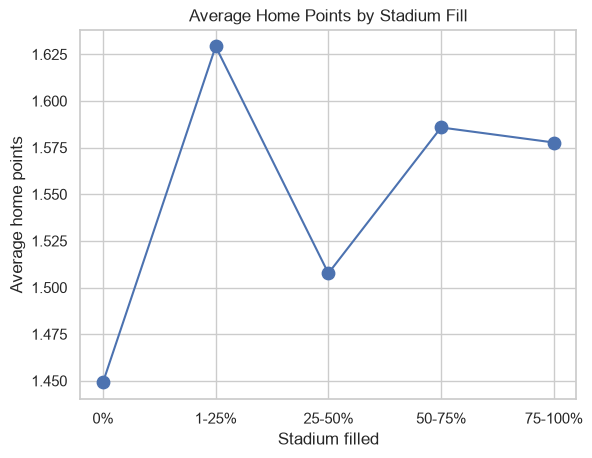

In [52]:
plt.scatter(by_size.index.astype(str), by_size["home_points"], s=80)
plt.plot(by_size.index.astype(str), by_size["home_points"])
plt.title("Average Home Points by Stadium Fill")
plt.xlabel("Stadium filled")
plt.ylabel("Average home points")
plt.show()

**Insight:** home points jump from **1.45** in empty stadiums to around **1.5–1.6** as soon as there's any crowd, and stay at about that level whether the stadium is a quarter full or completely full. The small-crowd groups have fewer matches (445 and 1,113), so their ups and downs are partly noise. The clear pattern is that the big difference is between **no fans and some fans**, not between a half-full and a full stadium.

### 4.5 Scatter: shots vs goals

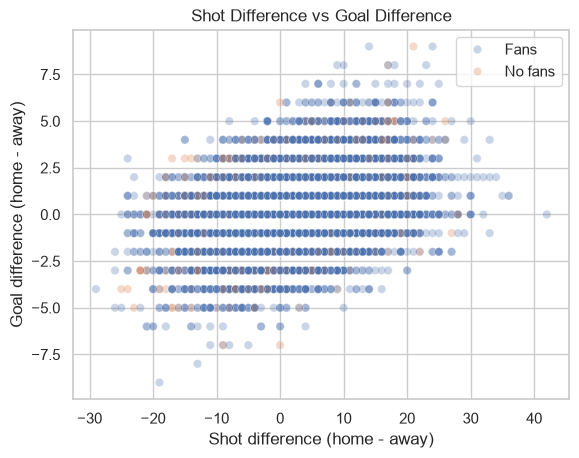

In [53]:
sns.scatterplot(data=df, x="shot_diff", y="goal_diff", hue="crowd_label", alpha=0.3)
plt.title("Shot Difference vs Goal Difference")
plt.xlabel("Shot difference (home - away)")
plt.ylabel("Goal difference (home - away)")
plt.legend(title="")
plt.show()

**Insight:** there's a positive but noisy relationship (correlation 0.33): teams that shoot more tend to score more, but many matches are won with fewer shots. The points overlap a lot, and ghost games sit in the same cloud as matches with fans. That suggests the crowd changes **how many shots** the home team gets (section 4.3) more than how shots turn into goals.

### 4.6 Correlation heatmap

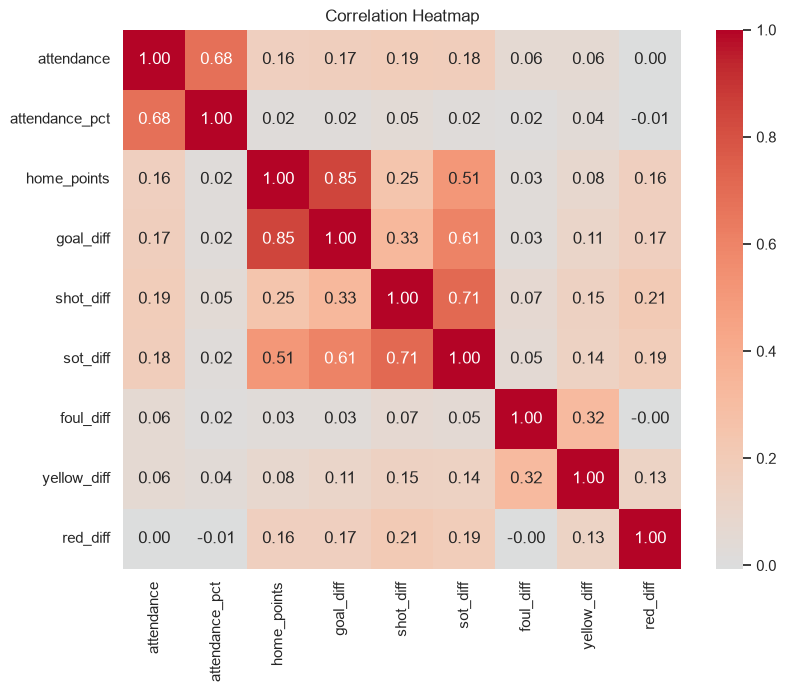

In [54]:
cols = ["attendance", "attendance_pct", "home_points", "goal_diff",
        "shot_diff", "sot_diff", "foul_diff", "yellow_diff", "red_diff"]

plt.figure(figsize=(9, 7))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Insight:**
- `attendance` correlates with `home_points` (0.16) and `shot_diff` (0.19) more than `attendance_pct` does (0.02). This is probably because **big clubs have big stadiums**: Barcelona and Bayern win at home because they're strong teams, not only because of the crowd. So raw attendance mixes crowd effect with team strength.
- `sot_diff` (shots on target) is linked to `goal_diff` much more strongly (0.61) than total shots (0.33). Accurate shots matter more than many shots.
- `foul_diff` and `yellow_diff` are linked (0.32): more fouls lead to more cards.
- All correlations with the crowd are weak. The crowd matters, but it's one factor among many.

## 5. Insights Summary

**Patterns discovered**
- Home advantage is real: home teams win 44% vs 31% for away teams.
- Without fans, home wins dropped from 45.0% (before COVID) to 39.9%, and away wins rose from 30.0% to 34.8%.
- When fans came back, home wins returned to 43.8%.

**Interesting relationships**
- **The referee:** with fans, away teams get +0.27 extra yellow cards per match. Without fans, the gap is 0. This is the strongest finding.
- **The players:** the home team's shot advantage halved without fans (2.6 → 1.35), so it's not only the referee.
- **Crowd size:** any crowd brings back most of the advantage. The key difference is fans vs no fans, not full vs half-full.

**Outliers**
- Very high attendances (70,000+) are real: Barcelona, Dortmund, Real Madrid.
- A few extreme goal differences (up to ±9) are real one-sided matches.

**Key takeaways**
1. Home advantage shrank by about two thirds without crowds: the gap between home and away wins went from 15 points (45.0% vs 30.0%) to 5 points (39.9% vs 34.8%), then came back to 13 points when fans returned.
2. Referee bias against away teams disappeared completely without crowds.
3. The effect differs by league: big in Ligue 1 and the Premier League, none in Serie A.
4. Raw attendance is mixed up with team strength, so stadium fill (`attendance_pct`) is a fairer measure of the crowd.